<a href="https://colab.research.google.com/github/tudorostin/diabetic-retinopathy-classification/blob/main/tema1IS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# organizare mediu colab-drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# dezarhivare
!unzip -q "/content/drive/MyDrive/Proiect_IS_Set_B/tema_IS_setB.zip" -d "/content/dataset_B/"

# verificare structura
!ls "/content/dataset_B/"

sl2026-retina-set-b


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import GroupShuffleSplit

# subfolderul extras din arhiva
BASE_DIR = '/content/dataset_B/sl2026-retina-set-b/'
IMAGES_DIR = os.path.join(BASE_DIR, 'images')
LABELS_PATH = os.path.join(BASE_DIR, 'labels.csv')

# incarcare fisier csv
df = pd.read_csv(LABELS_PATH)
print(df.head())

                  image  label   group source
0  images/img_00000.jpg      1  g08975     s1
1  images/img_00001.jpg      2  g07509     s1
2  images/img_00002.jpg      0  g05314     s1
3  images/img_00003.jpg      0  g06329     s2
4  images/img_00004.jpg      4  g07536     s2


Număr total de imagini în dataset: 10000
Dimensiunea imaginii extrase: (512, 512, 3)
Eticheta imaginii (Gradul de retinopatie): 1


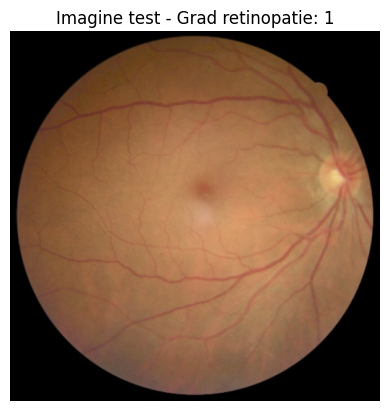

In [ ]:
import os
import cv2
import pandas as pd
import torch
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

class RetinopathyDataset(Dataset):
    def __init__(self, base_dir, indices=None, transform=None):
        self.base_dir = base_dir
        self.transform = transform

        # caile pentru imagini si etichete
        self.images_dir = os.path.join(self.base_dir, 'images')
        self.labels_path = os.path.join(self.base_dir, 'labels.csv')

        # csv cu maparea imaginilor
        self.data = pd.read_csv(self.labels_path)

        # filtrare dataframe dupa indici
        if indices is not None:
            self.data = self.data.iloc[indices].reset_index(drop=True)

    def __len__(self):
        # numarul total de imagini
        return len(self.data)

    def __getitem__(self, idx):
        # nume + eticheta pentru indexul curent
        img_name = self.data.iloc[idx]['image']
        label = int(self.data.iloc[idx]['label'])

        # calea completa catre imagine
        img_path = os.path.join(self.base_dir, img_name)

        # incarcare imagine OpenCV
        image = cv2.imread(img_path)

        # convertire BGR in RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # aplicare transformari
        if self.transform:
            image = self.transform(image)

        return image, label

# ==========================================
# TESTAREA CLASEI
# ==========================================
# Instanțiem dataset-ul complet (fără split și transformări momentan)
full_dataset = RetinopathyDataset(base_dir=BASE_DIR)

# Verificăm lungimea (metoda __len__)
print(f"Număr total de imagini în dataset: {len(full_dataset)}")

# Extragem prima imagine (metoda __getitem__)
img, lbl = full_dataset[0]

print(f"Dimensiunea imaginii extrase: {img.shape}")
print(f"Eticheta imaginii (Gradul de retinopatie): {lbl}")

# O afișăm pentru confirmare
plt.imshow(img)
plt.title(f"Imagine test - Grad retinopatie: {lbl}")
plt.axis('off')
plt.show()

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

def get_dataset_splits(df, n_splits=10, random_state=42):
    # fixare seed pentru reproductibilitate
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    # coloanele de interes
    X = df['image']
    y = df['label']
    groups = df['group']

    # generare fold uri
    folds = list(sgkf.split(X, y, groups))

    # fold-ul 0 pentru testare
    test_idx = folds[0][1]

    # fold-ul 1 pentru validare
    val_idx = folds[1][1]

    # restul pentru antrenare
    train_idx = np.setdiff1d(df.index, np.union1d(test_idx, val_idx))

    return train_idx, val_idx, test_idx

# generare indici
train_idx, val_idx, test_idx = get_dataset_splits(df, n_splits=10, random_state=42)

# verificare impartire
print(f"Total imagini: {len(df)}")
print(f"Antrenare (Train): {len(train_idx)} imagini ({len(train_idx)/len(df)*100:.1f}%)")
print(f"Validare (Val): {len(val_idx)} imagini ({len(val_idx)/len(df)*100:.1f}%)")
print(f"Testare (Test): {len(test_idx)} imagini ({len(test_idx)/len(df)*100:.1f}%)")

# verificare data leakage
train_groups = set(df.iloc[train_idx]['group'])
val_groups = set(df.iloc[val_idx]['group'])
test_groups = set(df.iloc[test_idx]['group'])

print("\n--- Verificare scurgeri de date (Data Leakage) ---")
print(f"Suprapunere pacienți Train vs Val: {len(train_groups.intersection(val_groups))}")
print(f"Suprapunere pacienți Train vs Test: {len(train_groups.intersection(test_groups))}")
print(f"Suprapunere pacienți Val vs Test: {len(val_groups.intersection(test_groups))}")

Total imagini: 10000
Antrenare (Train): 8005 imagini (80.0%)
Validare (Val): 996 imagini (10.0%)
Testare (Test): 999 imagini (10.0%)

--- Verificare scurgeri de date (Data Leakage) ---
Suprapunere pacienți Train vs Val: 0
Suprapunere pacienți Train vs Test: 0
Suprapunere pacienți Val vs Test: 0


/tmp/ipykernel_378/3606733137.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=train_labels, ax=axes[0], order=clase, palette='Blues_r')
/tmp/ipykernel_378/3606733137.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=val_labels, ax=axes[1], order=clase, palette='Greens_r')
/tmp/ipykernel_378/3606733137.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=test_labels, ax=axes[2], order=clase, palette='Reds_r')


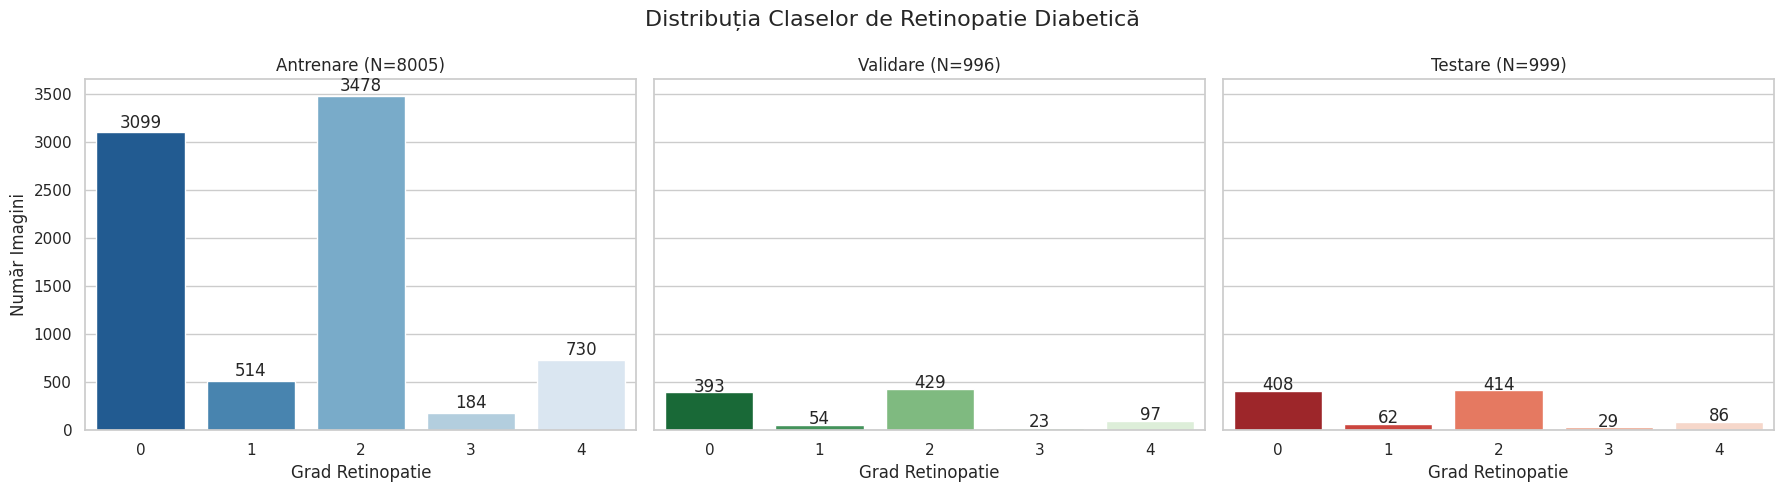


Am salvat graficul in: /content/drive/MyDrive/Proiect_IS_Set_B/Distributie_Clase.png

=== Distribuția Procentuală pe clase ===
                  Antrenare (%)  Validare (%)  Testare (%)
Grad Retinopatie                                          
0                         38.71         39.46        40.84
1                          6.42          5.42         6.21
2                         43.45         43.07        41.44
3                          2.30          2.31         2.90
4                          9.12          9.74         8.61
Am salvat tabelul in: /content/drive/MyDrive/Proiect_IS_Set_B/Procente_Clase.csv


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# subseturi de etichete
train_labels = df.iloc[train_idx]['label']
val_labels = df.iloc[val_idx]['label']
test_labels = df.iloc[test_idx]['label']

clase = sorted(df['label'].unique())

# aspectul vizual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Distribuția Claselor de Retinopatie Diabetică', fontsize=16)

# antrenare
sns.countplot(x=train_labels, ax=axes[0], order=clase, palette='Blues_r')
axes[0].set_title(f'Antrenare (N={len(train_labels)})')
axes[0].set_xlabel('Grad Retinopatie')
axes[0].set_ylabel('Număr Imagini')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + 0.4, p.get_height() + 50), ha='center')

# validare
sns.countplot(x=val_labels, ax=axes[1], order=clase, palette='Greens_r')
axes[1].set_title(f'Validare (N={len(val_labels)})')
axes[1].set_xlabel('Grad Retinopatie')
axes[1].set_ylabel('')

for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + 0.4, p.get_height() + 10), ha='center')

# testare
sns.countplot(x=test_labels, ax=axes[2], order=clase, palette='Reds_r')
axes[2].set_title(f'Testare (N={len(test_labels)})')
axes[2].set_xlabel('Grad Retinopatie')
axes[2].set_ylabel('')

for p in axes[2].patches:
    axes[2].annotate(f'{int(p.get_height())}', (p.get_x() + 0.4, p.get_height() + 10), ha='center')

plt.tight_layout()

# salvare in drive si afisare grafic
GRAFIC_PATH = '/content/drive/MyDrive/Proiect_IS_Set_B/Distributie_Clase.png'
plt.savefig(GRAFIC_PATH, dpi=300, bbox_inches='tight', facecolor='white')

plt.show()

print(f"\nAm salvat graficul in: {GRAFIC_PATH}")

# generare si salvare tabel in drive
print("\n=== Distribuția Procentuală pe clase ===")
dist_df = pd.DataFrame({
    'Antrenare (%)': (train_labels.value_counts(normalize=True).sort_index() * 100).round(2),
    'Validare (%)': (val_labels.value_counts(normalize=True).sort_index() * 100).round(2),
    'Testare (%)': (test_labels.value_counts(normalize=True).sort_index() * 100).round(2)
})
dist_df.index.name = 'Grad Retinopatie'
print(dist_df)

CSV_PATH = '/content/drive/MyDrive/Proiect_IS_Set_B/Procente_Clase.csv'
dist_df.to_csv(CSV_PATH)
print(f"Am salvat tabelul in: {CSV_PATH}")

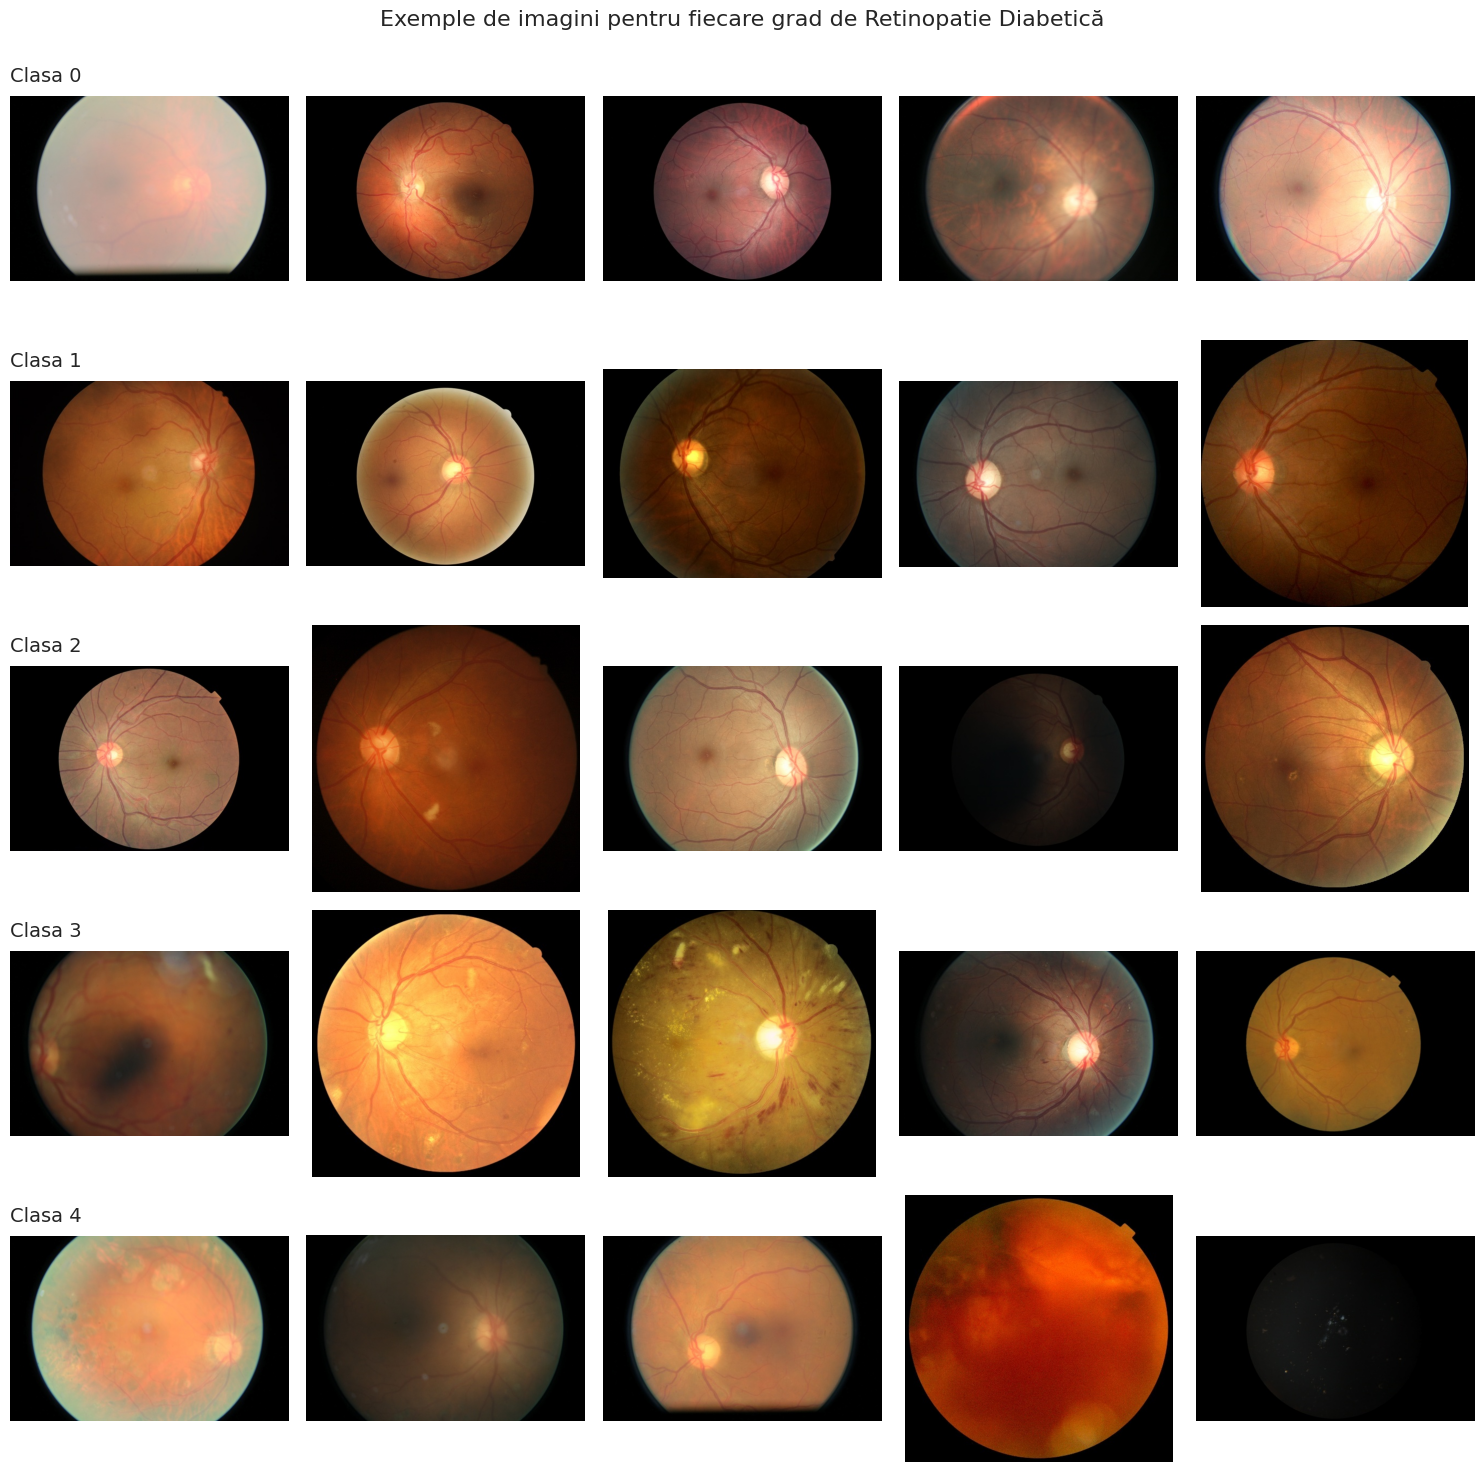


Imaginea cu exemple am salvat o in: /content/drive/MyDrive/Proiect_IS_Set_B/Exemple_Clase.png


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

# fixare seed
random.seed(42)

num_classes = 5
images_per_class = 5

# creare grila sub-ploturi de 5x5
fig, axes = plt.subplots(num_classes, images_per_class, figsize=(15, 15))
fig.suptitle('Exemple de imagini pentru fiecare grad de Retinopatie Diabetică', fontsize=16)

for label in range(num_classes):
    # filtrare dataframe oentru imaginile din aceiasi clasa
    class_df = df[df['label'] == label]

    # random 5 imagini din acea clasa
    sample_images = class_df.sample(images_per_class, random_state=42)['image'].values

    for i, img_name in enumerate(sample_images):
        # calea catre imagine
        img_path = os.path.join(BASE_DIR, img_name)

        # incarcare + convertire din BGR in RGB
        image = cv2.imread(img_path)
        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        else:
            print(f"Eroare la încărcarea imaginii: {img_path}")
            continue

        # afisare sub-plot
        ax = axes[label, i]
        ax.imshow(image)
        ax.axis('off') # fara axe

        # titlul clasei
        if i == 0:
            ax.set_title(f'Clasa {label}', fontsize=14, loc='left', pad=10)

plt.tight_layout()
plt.subplots_adjust(top=0.95)

# afisarea si salvarea grile in drive
EXEMPLE_PATH = '/content/drive/MyDrive/Proiect_IS_Set_B/Exemple_Clase.png'
plt.savefig(EXEMPLE_PATH, dpi=300, bbox_inches='tight', facecolor='white')

plt.show()

print(f"\nImaginea cu exemple am salvat o in: {EXEMPLE_PATH}")

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

print("Analizare 10000 imagini")

dimensiuni = []
canale = []
valori_minime = []
valori_maxime = []

# toate caile din dataframe ul curent
for img_name in tqdm(df['image'].values):
    img_path = os.path.join(BASE_DIR, img_name)

    # citire imagine
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)

    if img is None:
        continue

    # verificare nr canale
    if len(img.shape) == 2:
        # alb-negru
        c = 1
    else:
        # color (RGB/BGR sau RGBA)
        c = img.shape[2]

    canale.append(c)
    dimensiuni.append((img.shape[1], img.shape[0]))
    valori_minime.append(img.min())
    valori_maxime.append(img.max())

# statisticile
unique_dims = pd.Series(dimensiuni).value_counts()
unique_channels = pd.Series(canale).value_counts()

print("\n=== REZULTATE ANALIZĂ CERINȚA 5 ===")
print("\n1. Distribuția numărului de canale:")
print(unique_channels)

print("\n2. Top 5 Dimensiuni (Lățime x Înălțime) găsite în dataset:")
print(unique_dims.head())
print(f"Număr total de rezoluții diferite: {len(unique_dims)}")

print("\n3. Scala valorilor pixelilor:")
print(f"Valoarea minimă absolută găsită: {min(valori_minime)}")
print(f"Valoarea maximă absolută găsită: {max(valori_maxime)}")

Analizare 10000 imagini


  0%|          | 0/10000 [00:00<?, ?it/s]


=== REZULTATE ANALIZĂ CERINȚA 5 ===

1. Distribuția numărului de canale:
3    10000
Name: count, dtype: int64

2. Top 5 Dimensiuni (Lățime x Înălțime) găsite în dataset:
(512, 341)    4132
(512, 512)    3336
(512, 384)    1366
(512, 339)     306
(512, 340)     227
Name: count, dtype: int64
Număr total de rezoluții diferite: 25

3. Scala valorilor pixelilor:
Valoarea minimă absolută găsită: 0
Valoarea maximă absolută găsită: 255


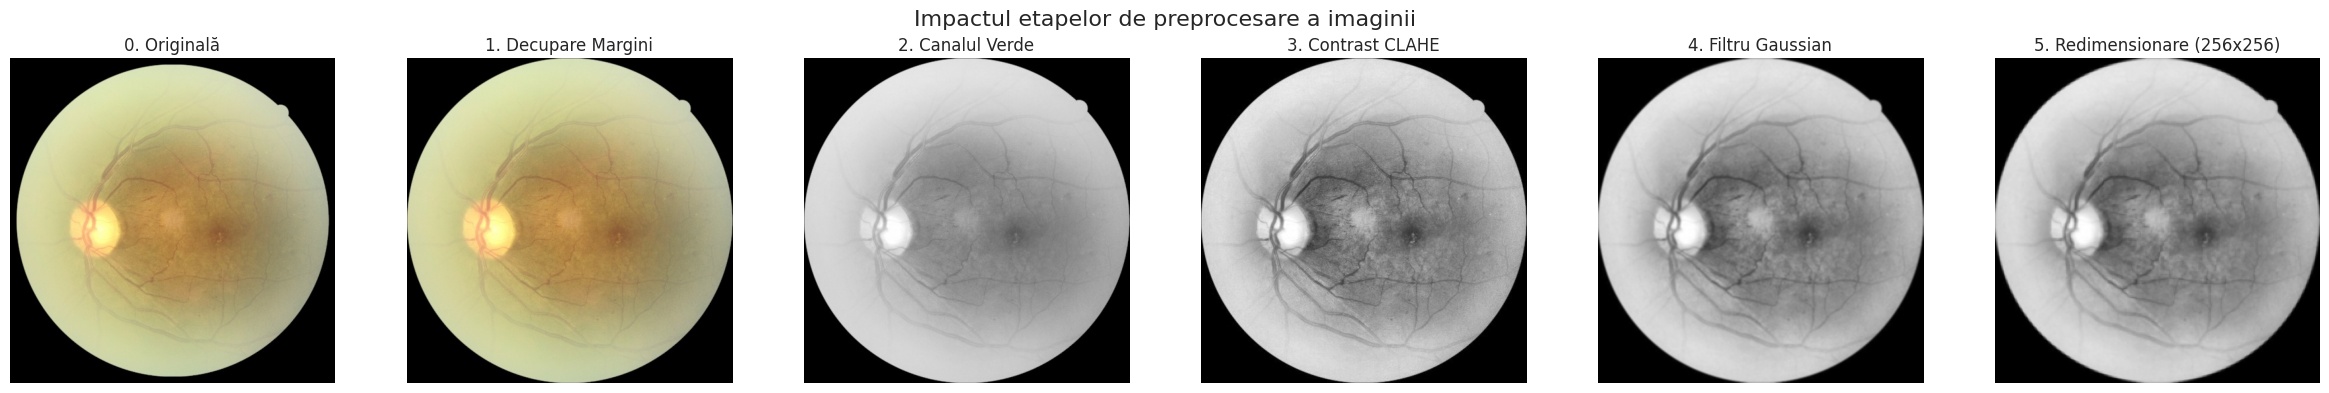


Imaginea cu pasii de preprocesare am salvat o in: /content/drive/MyDrive/Proiect_IS_Set_B/Preprocesare_Pasi.png


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def crop_black_borders(image):
    """ eliminare margini negre inutile din jurul ochiului. """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        return image[y:y+h, x:x+w]
    return image

def extract_green_channel(image):
    """ extragere canal verde """
    return image[:, :, 1]

def apply_clahe(image_gray):
    """ CLAHE pentru contrast local adaptiv """
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image_gray)

def apply_gaussian_blur(image_gray):
    """ filtru gaussian pentru a reduce zgomotul """
    return cv2.GaussianBlur(image_gray, (5, 5), 0)

def resize_image(image, size=(256, 256)):
    """ redimensionare imagine la o forma fixa """
    return cv2.resize(image, size)

# testare si vizualizare pe o imagine

# fie imaginea 10 din dataframe
img_name_test = df.iloc[10]['image']
img_path_test = os.path.join(BASE_DIR, img_name_test)

# incarcare imagine originala
img_original = cv2.cvtColor(cv2.imread(img_path_test), cv2.COLOR_BGR2RGB)

# aplicare pipeline
img_step1 = crop_black_borders(img_original)
img_step2 = extract_green_channel(img_step1)
img_step3 = apply_clahe(img_step2)
img_step4 = apply_gaussian_blur(img_step3)
img_step5 = resize_image(img_step4, size=(256, 256))

# creare grafic
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
fig.suptitle('Impactul etapelor de preprocesare a imaginii', fontsize=16)

axes[0].imshow(img_original)
axes[0].set_title('0. Originală')
axes[0].axis('off')

axes[1].imshow(img_step1)
axes[1].set_title('1. Decupare Margini')
axes[1].axis('off')

axes[2].imshow(img_step2, cmap='gray')
axes[2].set_title('2. Canalul Verde')
axes[2].axis('off')

axes[3].imshow(img_step3, cmap='gray')
axes[3].set_title('3. Contrast CLAHE')
axes[3].axis('off')

axes[4].imshow(img_step4, cmap='gray')
axes[4].set_title('4. Filtru Gaussian')
axes[4].axis('off')

axes[5].imshow(img_step5, cmap='gray')
axes[5].set_title('5. Redimensionare (256x256)')
axes[5].axis('off')

plt.tight_layout()

# salvare imagine in drive pentru raport
PREPROC_PATH = '/content/drive/MyDrive/Proiect_IS_Set_B/Preprocesare_Pasi.png'
plt.savefig(PREPROC_PATH, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\nImaginea cu pasii de preprocesare am salvat o in: {PREPROC_PATH}")

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights
import numpy as np
import cv2
from PIL import Image

# 1. preprocesarea in transformer PyTorch
class FundusPreprocessing:
    def __call__(self, img_array):
        # decupare
        gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
        _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            img_array = img_array[y:y+h, x:x+w]

        # extragere canal verde
        green_channel = img_array[:, :, 1]

        # CLAHE
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced = clahe.apply(green_channel)

        # flitru gaussian
        blurred = cv2.GaussianBlur(enhanced, (5, 5), 0)

        # convertire la 3 canale
        img_3c = cv2.cvtColor(blurred, cv2.COLOR_GRAY2RGB)

        # PIL Image pt compatibilitate Pytorch
        return Image.fromarray(img_3c)

# pipeline de transformati
transform = transforms.Compose([
    FundusPreprocessing(),
    transforms.Resize((256, 256)), # resize
    transforms.ToTensor(),         # normalizare + conversie in tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# instantiere dataset si dataLoaders (indicii sunt aceiasi ca la cerinta 2)
train_dataset = RetinopathyDataset(base_dir=BASE_DIR, indices=train_idx, transform=transform)
val_dataset = RetinopathyDataset(base_dir=BASE_DIR, indices=val_idx, transform=transform)
test_dataset = RetinopathyDataset(base_dir=BASE_DIR, indices=test_idx, transform=transform)

# configurare dataLoader
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# calcul ponderile ale claselor (pe cele minoritare penalizam mai mult)
class_counts = df.iloc[train_idx]['label'].value_counts().sort_index().values
total_samples = len(train_idx)
class_weights = total_samples / (len(class_counts) * class_counts)
class_weights = torch.FloatTensor(class_weights).cuda()

print(f"Ponderi clase (0->4): {class_weights.cpu().numpy().round(2)}")

# baseline - ResNet18 cu pre-antrenare
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
# modificare ultim strat
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 5)
model = model.to(device)

# loss function + Adam
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=1e-4) # rata de invatare mica

print("Setup finalizat. Modelul este gata pentru antrenare!")

Ponderi clase (0->4): [0.52 3.11 0.46 8.7  2.19]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 204MB/s]


Setup finalizat. Modelul este gata pentru antrenare!


Începem antrenarea pe cuda pentru 10 epoci...

Epoca 01/10 | Train Loss: 1.2248 Acc: 0.4256 | Val Loss: 1.2853 Acc: 0.5482 | Timp: 83s
Epoca 02/10 | Train Loss: 0.9115 Acc: 0.5535 | Val Loss: 1.2104 Acc: 0.4759 | Timp: 77s
Epoca 03/10 | Train Loss: 0.6194 Acc: 0.6740 | Val Loss: 1.3606 Acc: 0.5703 | Timp: 75s
Epoca 04/10 | Train Loss: 0.3272 Acc: 0.8119 | Val Loss: 1.2919 Acc: 0.5231 | Timp: 77s
Epoca 05/10 | Train Loss: 0.1625 Acc: 0.9151 | Val Loss: 2.0781 Acc: 0.6135 | Timp: 76s
Epoca 06/10 | Train Loss: 0.0928 Acc: 0.9567 | Val Loss: 1.7635 Acc: 0.6064 | Timp: 77s
Epoca 07/10 | Train Loss: 0.0429 Acc: 0.9844 | Val Loss: 2.0578 Acc: 0.6325 | Timp: 76s
Epoca 08/10 | Train Loss: 0.0285 Acc: 0.9888 | Val Loss: 2.2065 Acc: 0.6355 | Timp: 76s
Epoca 09/10 | Train Loss: 0.0724 Acc: 0.9634 | Val Loss: 2.3505 Acc: 0.5904 | Timp: 75s
Epoca 10/10 | Train Loss: 0.2443 Acc: 0.8851 | Val Loss: 2.0582 Acc: 0.5141 | Timp: 75s

--- Antrenare Completa. Incarcam cel mai bun model pentru Evaluarea Fina

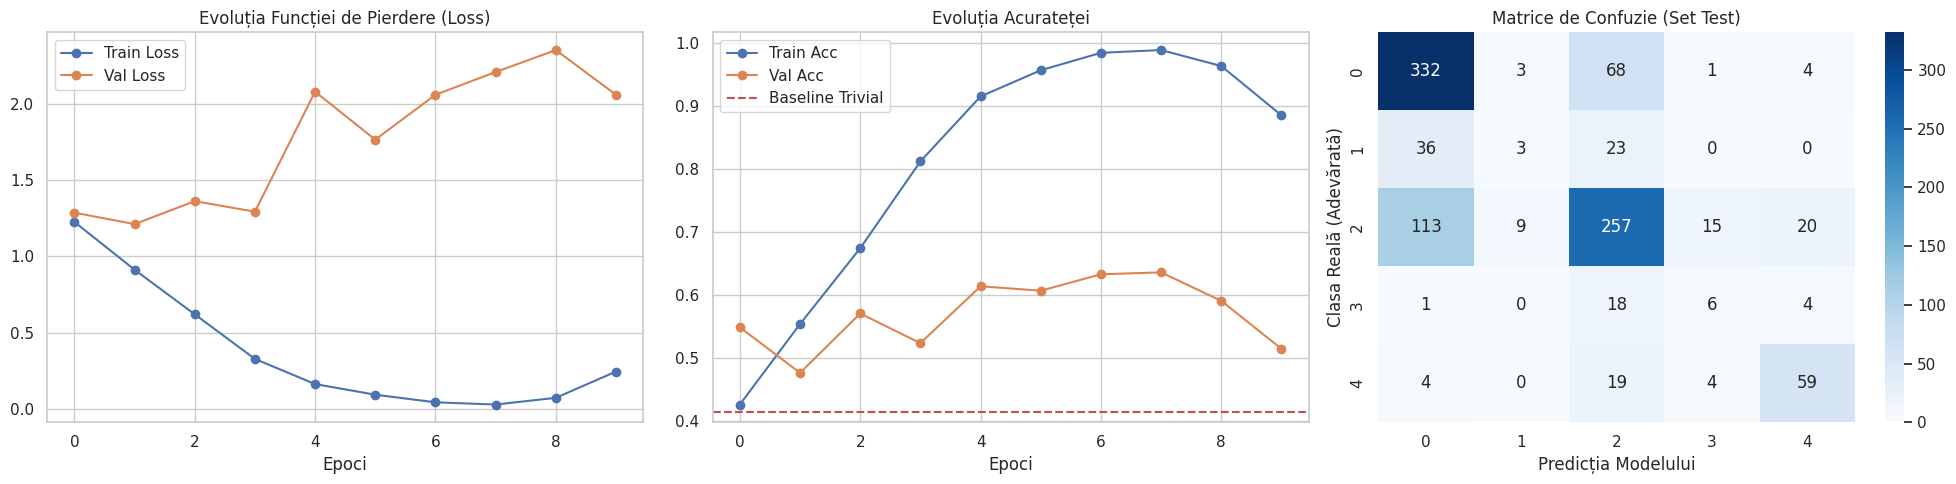


Graficele finale au fost salvate în: /content/drive/MyDrive/Proiect_IS_Set_B/Evaluare_Model.png


In [ ]:
import time
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import copy

num_epochs = 10 # n are sens mai mult ptc degradez generalizarea
best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

# Istoric pentru grafice
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"Începem antrenarea pe {device} pentru {num_epochs} epoci...\n")

for epoch in range(num_epochs):
    start_time = time.time()

    # ANTRENARE
    model.train()
    running_loss, running_corrects = 0.0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = running_corrects.double() / len(train_dataset)
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc.item())

    # VALIDARE
    model.eval()
    val_loss, val_corrects = 0.0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = val_corrects.double() / len(val_dataset)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc.item())

    # salvare cel mai bun model dupa val
    if epoch_val_acc > best_acc:
        best_acc = epoch_val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), '/content/drive/MyDrive/Proiect_IS_Set_B/best_baseline_model.pth')

    time_elapsed = time.time() - start_time
    print(f'Epoca {epoch+1:02d}/{num_epochs} | '
          f'Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | '
          f'Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f} | '
          f'Timp: {time_elapsed:.0f}s')

print("\n--- Antrenare Completa. Incarcam cel mai bun model pentru Evaluarea Finala pe Test ---")
model.load_state_dict(best_model_wts)
model.eval()

test_preds, test_labels_list = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels_list.extend(labels.cpu().numpy())

# baseline comparativ care prezice mereu clasa majoritara - clasa 2
majority_class = df.iloc[train_idx]['label'].mode()[0]
dummy_preds = [majority_class] * len(test_labels_list)
dummy_acc = accuracy_score(test_labels_list, dummy_preds)

# raportul de clasificare
print("\n=== Raport Evaluare (Set Testare) ===")
print(classification_report(test_labels_list, test_preds, digits=4))
final_acc = accuracy_score(test_labels_list, test_preds)
print(f"Acuratețe Model Deep Learning: {final_acc*100:.2f}%")
print(f"Acuratețe Strategie Trivială (prezice mereu clasa {majority_class}): {dummy_acc*100:.2f}%")

# grafice + matricea de confuzie
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Grafic 1: Loss
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='o')
axes[0].set_title('Evoluția Funcției de Pierdere (Loss)')
axes[0].set_xlabel('Epoci')
axes[0].legend()

# Grafic 2: Acuratețe
axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history['val_acc'], label='Val Acc', marker='o')
axes[1].axhline(y=dummy_acc, color='r', linestyle='--', label='Baseline Trivial')
axes[1].set_title('Evoluția Acurateței')
axes[1].set_xlabel('Epoci')
axes[1].legend()

# Grafic 3: Matrice de Confuzie
cm = confusion_matrix(test_labels_list, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Matrice de Confuzie (Set Test)')
axes[2].set_xlabel('Predicția Modelului')
axes[2].set_ylabel('Clasa Reală (Adevărată)')

plt.tight_layout()
EVAL_PATH = '/content/drive/MyDrive/Proiect_IS_Set_B/Evaluare_Model.png'
plt.savefig(EVAL_PATH, dpi=300, facecolor='white')
plt.show()

print(f"\nGraficele finale au fost salvate în: {EVAL_PATH}")